# 2장 라플라스 근사와 동역학 생성 모델 (실습)

이 노트북이 답하는 질문은 셋이다.

1. 라플라스 근사 아래의 자유 에너지는 정확한 자유 에너지와 얼마나 가까운가, 그리고 언제 멀어지는가?
2. 행렬로 쓴 자유 에너지 ½εᵀΠε − ½ln|Π| 는 정말 정밀도로 가중한 예측 오차의 제곱합인가?
3. 유색 잡음을 일반화 좌표로 펼치면 높은 차수의 도함수는 얼마나 믿을 만한가? 이론이 내놓은 시간 공분산 행렬 S(s²) 가 실제 잡음과 맞는가?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz, inv

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

def gauss(x, m, s2):
    """평균 m, 분산 s2 인 가우스 밀도."""
    return np.exp(-(x - m)**2 / (2 * s2)) / np.sqrt(2 * np.pi * s2)

print("준비 완료, numpy", np.__version__)

준비 완료, numpy 2.5.4


## 1. 라플라스 근사는 얼마나 정확한가

감각 사상을 비선형 g(x) = x² 로 두고 관측 y = 4 를 받는다. 사전 믿음은 N(1, 1) 이다. 감각 잡음의 분산을 바꿔 가며 세 값을 비교한다.

- 기준선: 격자 위에서 분모를 적분해 얻은 정확한 놀람 −ln p(y) 와 사후 평균
- 라플라스 근사: 경사 하강으로 찾은 μ* 와, 그 자리의 곡률로 정한 분산으로 계산한 자유 에너지 F_L = −ln p(y, μ*) − ½ ln(2π σ_q²)

정확한 자유 에너지의 최솟값은 놀람이므로 F_L 과 놀람의 차이가 곧 라플라스 근사의 오차다.

In [2]:
v, s2_w, y = 1.0, 1.0, 4.0
g, dg, d2g = (lambda x: x**2), (lambda x: 2 * x), (lambda x: 2.0)
xs = np.linspace(-6, 6, 60001)
dx = xs[1] - xs[0]

def laplace_vs_exact(s2_z):
    joint = gauss(y, g(xs), s2_z) * gauss(xs, v, s2_w)
    evidence = joint.sum() * dx
    post_mean = (xs * joint).sum() * dx / evidence
    m = v
    for _ in range(20000):                       # 자유 에너지 경사 하강
        m -= 0.0005 * (-(y - g(m)) * dg(m) / s2_z + (m - v) / s2_w)
    curv = (dg(m)**2 - (y - g(m)) * d2g(m)) / s2_z + 1 / s2_w
    s2_q = 1 / curv                              # 라플라스 근사의 분산
    F_L = -np.log(gauss(y, g(m), s2_z) * gauss(m, v, s2_w)) - 0.5 * np.log(2 * np.pi * s2_q)
    return m, post_mean, s2_q, F_L, -np.log(evidence)

print("감각분산   μ*    사후평균   σ_q²     F_L    놀람    오차")
for s2_z in [0.05, 0.5, 2.0, 8.0]:
    m, pm, s2q, FL, S = laplace_vs_exact(s2_z)
    print(f"{s2_z:6.2f}  {m:6.3f}  {pm:6.3f}  {s2q:7.4f}  {FL:6.3f}  {S:6.3f}  {FL - S:+.3f}")

감각분산   μ*    사후평균   σ_q²     F_L    놀람    오차
  0.05   1.997   1.922   0.0031   2.803   2.783  +0.020
  0.50   1.969   1.862   0.0317   2.782   2.748  +0.034
  2.00   1.879   1.609   0.1316   2.721   2.610  +0.111
  8.00   1.587   1.163   0.5291   2.586   2.465  +0.121


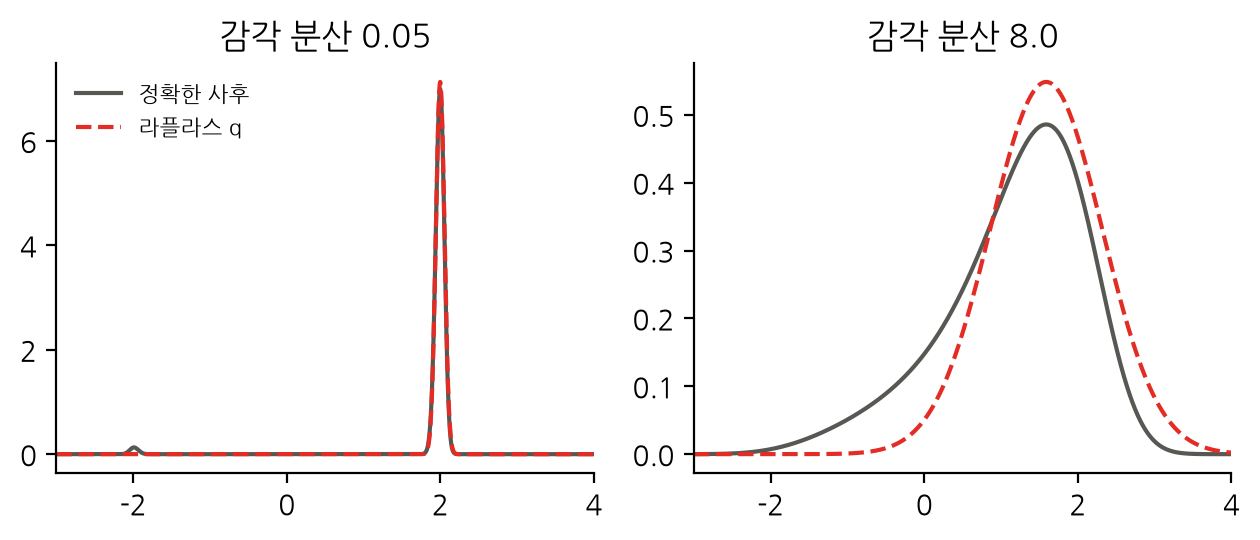

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.8), sharey=False)
for ax, s2_z in zip(axs, [0.05, 8.0]):
    joint = gauss(y, g(xs), s2_z) * gauss(xs, v, s2_w)
    post = joint / (joint.sum() * dx)
    m, _, s2q, _, _ = laplace_vs_exact(s2_z)
    ax.plot(xs, post, color="#575753", label="정확한 사후")
    ax.plot(xs, gauss(xs, m, s2q), "--", color="#E32C24", label="라플라스 q")
    ax.set_xlim(-3, 4); ax.set_title(f"감각 분산 {s2_z}")
axs[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 2. 행렬 꼴 자유 에너지

상태 두 개, 센서 세 개인 선형 생성 모델 y = Ax + z, 사전 x ~ N(η, Σ_w) 를 만든다. 예측 오차 벡터 ε 와 블록 대각 정밀도 행렬 Π 로 쓴 자유 에너지가 성분별 합과 같은지, 그리고 최소점이 닫힌 꼴의 베이즈 사후 평균과 같은지 확인한다.

In [4]:
rng = np.random.default_rng(0)
A = np.array([[1.0, 0.5], [0.0, 1.0], [2.0, -1.0]])    # g(x) = A x
eta = np.array([1.0, -0.5])                            # 사전 평균
Sz, Sw = np.diag([0.5, 1.0, 2.0]), np.diag([1.0, 4.0])
y_obs = A @ np.array([1.5, 0.0]) + rng.multivariate_normal(np.zeros(3), Sz)
Pi = inv(np.block([[Sz, np.zeros((3, 2))], [np.zeros((2, 3)), Sw]]))

def F_matrix(mu):
    eps = np.concatenate([y_obs - A @ mu, mu - eta])  # [ε_y; ε_x]
    return 0.5 * eps @ Pi @ eps - 0.5 * np.log(np.linalg.det(Pi))

def F_sum(mu):
    eps = np.concatenate([y_obs - A @ mu, mu - eta])
    var = np.r_[np.diag(Sz), np.diag(Sw)]
    return 0.5 * np.sum(eps**2 / var + np.log(var))

mu_star = np.linalg.solve(A.T @ inv(Sz) @ A + inv(Sw), A.T @ inv(Sz) @ y_obs + inv(Sw) @ eta)
mu = eta.copy()
for _ in range(2000):                                  # 경사 하강
    mu -= 0.05 * (-A.T @ inv(Sz) @ (y_obs - A @ mu) + inv(Sw) @ (mu - eta))
print(f"행렬 꼴 F = {F_matrix(mu):.6f},  합 꼴 F = {F_sum(mu):.6f}")
print("경사 하강 μ  =", np.round(mu, 4))
print("닫힌 꼴 사후 =", np.round(mu_star, 4))

행렬 꼴 F = 1.034513,  합 꼴 F = 1.034513
경사 하강 μ  = [1.6167 0.0475]
닫힌 꼴 사후 = [1.6167 0.0475]


## 3. 잡음 — 공분산 행렬로 백색 잡음 만들기

분산 3, 9, 16 인 독립 잡음 세 줄을 Cholesky 분해로 만들고 표본 공분산을 잰다. 이것이 유색 잡음과 비교할 기준선이다.

In [5]:
dt = 0.005                                  # 적분 간격 (초)
t = np.arange(0, 5 + dt / 2, dt)            # 5초, 1001 점
N = t.size
Sw3 = np.diag([3.0, 9.0, 16.0])
L = cholesky(Sw3, lower=True)
w_white = L @ np.random.randn(3, N)
print(f"데이터 점 {N}개, 간격 {dt}초")
print("표본 공분산 (목표 대각 3, 9, 16):")
print(np.round(np.cov(w_white), 2))

데이터 점 1001개, 간격 0.005초
표본 공분산 (목표 대각 3, 9, 16):
[[ 2.88  0.02  0.19]
 [ 0.02  8.93  0.13]
 [ 0.19  0.13 15.52]]


## 4. 유색 잡음

백색 잡음을 분산 s² 인 가우스 필터와 합성곱하면 시간적으로 매끄러운 잡음이 된다. s² 가 클수록 매끄럽다.

In [6]:
def makeNoise(C, s2, t):
    """공분산 C, 매끄러움 s2 (가우스 필터의 분산) 인 유색 잡음을 만든다."""
    C = np.atleast_2d(C)
    n, N = C.shape[1], np.size(t)
    w = cholesky(C, lower=True) @ np.random.randn(n, N)   # 공분산이 C 인 백색 잡음
    if s2 < 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))                 # 가우스 필터
    F = np.diag(1 / np.sqrt(np.diag(P.T @ P)))             # 분산이 보존되도록 정규화
    return w @ (P @ F)

np.random.seed(123456)
noises = {"백색": makeNoise(1.0, 0, t)}
for s2 in [1 / 512, 1 / 64, 1 / 4]:
    np.random.seed(123456)                                 # 같은 백색 잡음에서 출발
    noises[f"s²=1/{round(1 / s2)}"] = makeNoise(1.0, s2, t)
for name, n_ in noises.items():
    d1 = np.diff(n_[0]) / dt
    print(f"{name:9s} 분산 {n_[0].var():.2f}   1계 도함수 분산 {d1.var():10.1f}")

백색        분산 1.09   1계 도함수 분산    84445.8
s²=1/512  분산 1.44   1계 도함수 분산      287.6
s²=1/64   분산 1.71   1계 도함수 분산       50.8
s²=1/4    분산 1.04   1계 도함수 분산        4.1


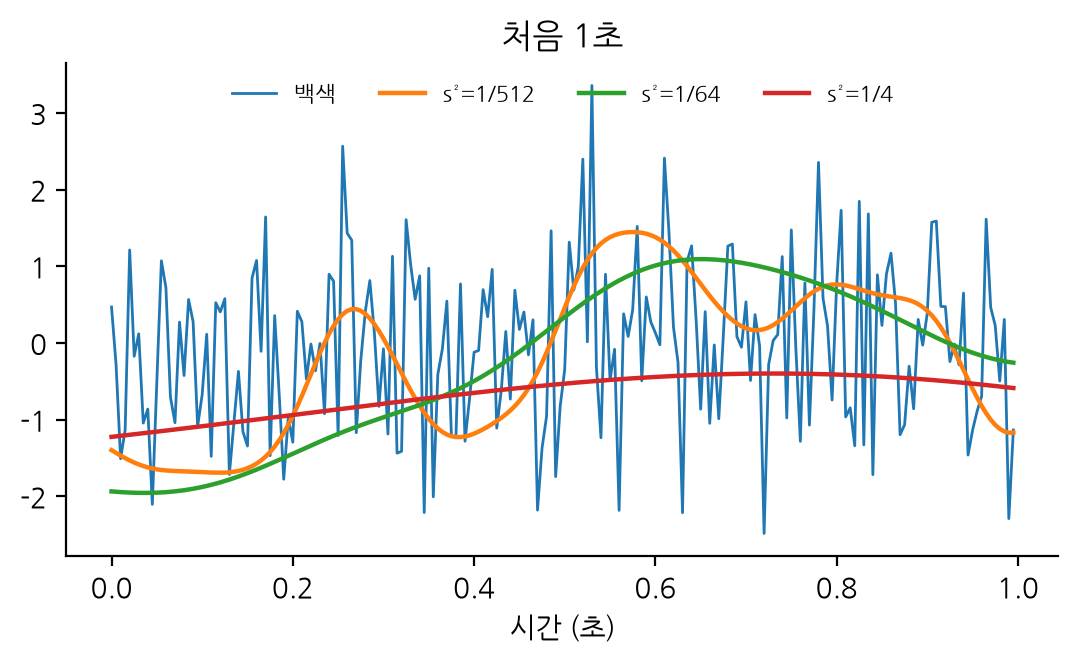

In [7]:
for name, n_ in noises.items():
    plt.plot(t[:200], n_[0, :200], lw=1.0 if name == "백색" else 1.6, label=name)
plt.xlabel("시간 (초)")
plt.title("처음 1초")
plt.legend(frameon=False, fontsize=8, ncol=4, loc="upper center")
plt.show()

## 5. 상태 공간 모델로 생성 과정 흉내 내기

숨은 상태 x 가 2 를 향해 이완하는 운동 방정식 ẋ = −0.8(x − 2) + w 와 감각 사상 y = 2x + 1 + z 를 오일러 방법으로 적분한다. 두 잡음 모두 유색이다.

x: 출발 0.00 → 끝 2.24 (평형 2.00)
y: 출발 1.02 → 끝 5.45 (평형 5.00)


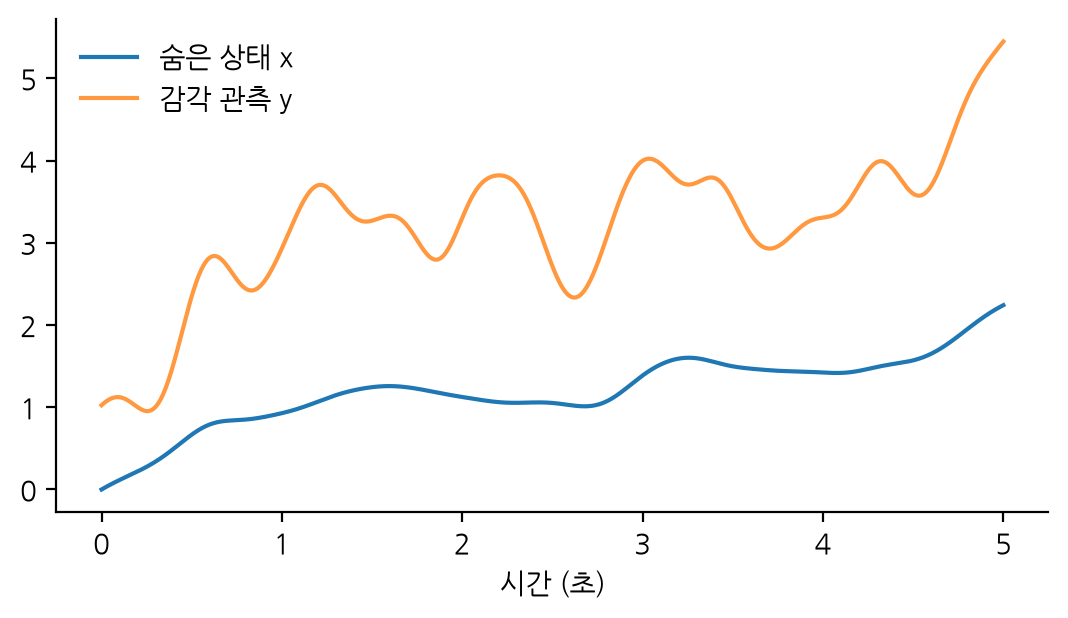

In [8]:
np.random.seed(7)
w = makeNoise(0.5, 1 / 64, t)[0]          # 상태 잡음
z = makeNoise(0.2, 1 / 64, t)[0]          # 감각 잡음
f = lambda x: -0.8 * (x - 2.0)            # 운동 방정식
g_ss = lambda x: 2.0 * x + 1.0            # 감각 사상

x = np.zeros(N)
for i in range(N - 1):
    x[i + 1] = x[i] + dt * (f(x[i]) + w[i])
y_ss = g_ss(x) + z
print(f"x: 출발 {x[0]:.2f} → 끝 {x[-1]:.2f} (평형 2.00)")
print(f"y: 출발 {y_ss[0]:.2f} → 끝 {y_ss[-1]:.2f} (평형 5.00)")
plt.plot(t, x, label="숨은 상태 x")
plt.plot(t, y_ss, label="감각 관측 y", alpha=0.8)
plt.xlabel("시간 (초)"); plt.legend(frameon=False)
plt.show()

## 6. 일반화 좌표와 미분 연산자 D

D 는 벡터를 한 칸 위로 밀고 맨 아래에 0 을 넣는다. 매끄러운 신호 sin(2t) 의 일반화 좌표를 수치 미분으로 만들고 해석적 도함수와 비교한다.

In [9]:
p = 3                                       # 임베딩 차수: 성분 p+1 = 4 개
D = np.eye(p + 1, k=1)
print("미분 연산자 D:")
print(D.astype(int))

sig = np.sin(2 * t)
tilde = [sig]
for _ in range(p):
    tilde.append(np.gradient(tilde[-1], dt))   # x, x', x'', x'''
tilde = np.array(tilde)
i = 300                                       # t = 1.5초
exact = np.array([np.sin(3), 2 * np.cos(3), -4 * np.sin(3), -8 * np.cos(3)])
print("t=1.5 의 일반화 좌표 (수치):", np.round(tilde[:, i], 3))
print("t=1.5 의 일반화 좌표 (해석):", np.round(exact, 3))
print("D x̃ (한 칸 위로):          ", np.round(D @ tilde[:, i], 3))

미분 연산자 D:
[[0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]
 [0 0 0 0]]
t=1.5 의 일반화 좌표 (수치): [ 0.141 -1.98  -0.564  7.92 ]
t=1.5 의 일반화 좌표 (해석): [ 0.141 -1.98  -0.564  7.92 ]
D x̃ (한 칸 위로):           [-1.98  -0.564  7.92   0.   ]


## 7. 시간 공분산 행렬 S(s²) 를 실제 잡음으로 검증한다

이론에 따르면 매끄러움 s² 인 유색 잡음의 k 계 도함수 분산은 S(s²) 의 대각선, 곧 1, 1/(2s²), 3/(2s²)², 15/(2s²)³ … 이다. 잡음 200 줄을 만들어 수치 미분한 분산과 비교한다.

In [10]:
def temporalC(p, s2):
    """임베딩 차수 p, 매끄러움 s2 인 잡음의 시간 공분산 행렬 S ((p+1)x(p+1))."""
    q = np.arange(p + 1)
    r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]])
        r = -r
    return S

s2 = 1 / 64
np.random.seed(11)
W = makeNoise(np.eye(200), s2, t)[:, 100:-100]          # 가장자리 효과를 피해 가운데만
emp, d = [], W
for k in range(3):
    emp.append(d.var())
    d = np.gradient(d, dt, axis=1)
theory = np.diag(temporalC(2, s2))
print("차수   실측 분산    S(s²) 대각선")
for k in range(3):
    print(f"{k}계  {emp[k]:10.1f}  {theory[k]:10.1f}")
print("S(s²=1) 의 일부:")
print(np.round(temporalC(3, 1.0), 3))

차수   실측 분산    S(s²) 대각선
0계         1.0         1.0
1계        32.6        32.0
2계      3139.8      3072.0
S(s²=1) 의 일부:
[[ 1.     0.    -0.5    0.   ]
 [-0.     0.5   -0.    -0.75 ]
 [-0.5    0.     0.75   0.   ]
 [-0.    -0.75  -0.     1.875]]


## 8. 일반화 자유 에너지에서 높은 차수의 무게

일반화 정밀도 Π̃ = S(s²)⁻¹ ⊗ Σ⁻¹ 의 대각선이 각 차수 예측 오차의 무게다. 잡음이 거칠수록(s² 가 작을수록) 높은 차수의 무게가 얼마나 빨리 줄어드는지 본다.

In [11]:
print("s²       0계      1계      2계      3계   (Σ=1, 무게를 0계로 나눈 값)")
for s2 in [1 / 4, 1 / 16, 1 / 64, 1 / 512]:
    Pi_t = inv(np.kron(temporalC(3, s2), np.eye(1)))
    wgt = np.diag(Pi_t) / Pi_t[0, 0]
    print(f"1/{round(1 / s2):<4d}" + "".join(f"{v:9.2e}" for v in wgt))

s²       0계      1계      2계      3계   (Σ=1, 무게를 0계로 나눈 값)
1/4    1.00e+00 8.33e-01 8.33e-02 1.39e-02
1/16   1.00e+00 2.08e-01 5.21e-03 2.17e-04
1/64   1.00e+00 5.21e-02 3.26e-04 3.39e-06
1/512  1.00e+00 6.51e-03 5.09e-06 6.62e-09


## 9. 실패 조건 — 짧은 기록으로는 매끄러운 잡음의 분산을 못 믿는다

매끄러운 잡음은 이웃한 값들이 강하게 상관되어 있어 실제로 독립인 표본 수가 적다. 같은 공분산(분산 9)으로 잡음을 다섯 번 만들어 5초 기록의 표본 분산이 얼마나 흔들리는지 잰다.

In [12]:
print("s²       5번 실행한 표본 분산 (목표 9)          표준편차")
for s2 in [0, 1 / 512, 1 / 64, 1 / 4]:
    vals = []
    for seed in range(5):
        np.random.seed(100 + seed)
        vals.append(makeNoise(9.0, s2, t)[0].var())
    name = "백색 " if s2 == 0 else f"1/{round(1 / s2):<4d}"
    print(f"{name}  " + " ".join(f"{v:6.2f}" for v in vals) + f"   {np.std(vals):6.2f}")

s²       5번 실행한 표본 분산 (목표 9)          표준편차
백색     9.83   9.97   8.69   8.79   8.73     0.57


1/512    10.10   6.39   7.98   7.00   7.07     1.30


1/64     11.95   5.42   6.53  10.10   5.73     2.61
1/4       7.02   1.36   1.53   8.57   2.96     2.96


## 결론

- 감각이 정밀해 사후 분포가 뾰족할수록 라플라스 자유 에너지는 정확한 놀람에 가깝다. 감각 분산이 커져 사후 분포가 넓고 비대칭이 되면 오차가 커진다.
- 행렬 꼴 자유 에너지는 성분별 정밀도 가중 제곱합과 같고, 그 최소점은 선형-가우스 모델의 닫힌 꼴 사후 평균과 같다.
- 유색 잡음의 도함수 분산은 시간 공분산 행렬 S(s²) 의 대각선과 맞는다. 잡음이 거칠수록 높은 차수의 정밀도는 급격히 작아져, 일반화 자유 에너지에서 거의 무시된다.
- 매끄러운 잡음은 짧은 기록에서 표본 분산이 크게 흔들린다. 시뮬레이션의 잡음 수준을 표본 분산으로 확인할 때 조심해야 한다.